# Voice of Customer Intelligence com RAG
## 01 · Análise Exploratória de Dados (EDA) — Olist

**FIAP Pós-Tech · AI Scientist · Tech Challenge — Fase 4**

> **Objetivo:** entender a disponibilidade, a qualidade e o contexto das avaliações dos consumidores antes de construir a base de conhecimento do RAG.

**Como executar:** rode as células **na ordem**, usando o kernel do ambiente virtual `.venv` do projeto. Analise cada saída antes de avançar. Este notebook **não altera os CSVs originais** e **não grava arquivos processados**.

**Dependências locais:** `pandas`, `numpy`, `matplotlib`, `ipykernel`.

**Fonte:** [Brazilian E-Commerce Public Dataset by Olist (Kaggle)](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce/data)

**Questões que queremos responder:**

1. Quantas avaliações possuem texto aproveitável?
2. Como notas e disponibilidade de comentários se relacionam?
3. Há duplicidades, textos genéricos ou registros inconsistentes?
4. Quais informações de pedidos, entrega e produtos podem enriquecer a recuperação?
5. Quais decisões de tratamento são justificadas pelos dados?

### Roteiro da análise

| Seção | Conteúdo |
|:--|:--|
| **1. Ambiente e arquivos** | Imports, localização do projeto e inventário de CSVs |
| **2. Avaliações** | Schema, nulos e disponibilidade de texto |
| **3. Qualidade e integridade** | IDs, duplicidades, notas e datas |
| **4. Notas e comentários** | Distribuições e cobertura por nota |
| **5. Análise textual** | Comprimento, mensagens repetidas e termos frequentes |
| **6. Enriquecimento** | Relacionamento com pedidos, entregas e produtos |
| **7. Conclusões** | Resumo e decisões para a futura ingestão RAG |

> **Nota metodológica:** análise exploratória não é indexação. Não faremos embeddings, exclusão definitiva de registros nem chamada a LLM nesta etapa.

## 1. Ambiente e arquivos

In [22]:
from pathlib import Path
from collections import Counter
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 100)
plt.style.use("default")


def localizar_raiz_projeto():
    # Aceita execução com o kernel iniciado na raiz ou em notebooks/.
    for pasta in (Path.cwd(), *Path.cwd().parents):
        if (pasta / "data" / "raw" / "olist_order_reviews_dataset.csv").is_file():
            return pasta
    raise FileNotFoundError(
        "Não encontrei data/raw/olist_order_reviews_dataset.csv. "
        "Abra o projeto no VS Code e confira o diretório de trabalho do kernel."
    )


RAIZ = localizar_raiz_projeto()
RAW = RAIZ / "data" / "raw"
print("Raiz do projeto:", RAIZ)
print("Diretório de dados:", RAW)
print("Versão do Pandas:", pd.__version__)

Raiz do projeto: c:\Users\vinic\repos\tech-challenge-4-voice-of-customer-rag
Diretório de dados: c:\Users\vinic\repos\tech-challenge-4-voice-of-customer-rag\data\raw
Versão do Pandas: 3.1.1


In [23]:
arquivos = sorted(RAW.glob("*.csv"))
inventario = pd.DataFrame({
    "arquivo": [p.name for p in arquivos],
    "tamanho_mb": [round(p.stat().st_size / (1024 ** 2), 2) for p in arquivos],
})
display(inventario)
print(f"Arquivos CSV: {len(inventario)} | Total: {inventario['tamanho_mb'].sum():.1f} MiB")

,arquivo,tamanho_mb
0,olist_customers_dataset.csv,8.62
1,olist_geolocation_dataset.csv,58.44
2,olist_order_items_dataset.csv,14.72
3,olist_order_payments_dataset.csv,5.51
4,olist_order_reviews_dataset.csv,13.78
5,olist_orders_dataset.csv,16.84
6,olist_products_dataset.csv,2.27
7,olist_sellers_dataset.csv,0.17
8,product_category_name_translation.csv,0.00


Arquivos CSV: 9 | Total: 120.3 MiB


## 2. Entendendo a tabela principal de avaliações

O arquivo `olist_order_reviews_dataset.csv` contém notas e, quando disponíveis, títulos e mensagens. **Uma nota sem comentário não constitui evidência textual para o nosso RAG.**

In [24]:
reviews = pd.read_csv(
    RAW / "olist_order_reviews_dataset.csv",
    dtype={"review_id": "string", "order_id": "string"},
)
colunas_originais = list(reviews.columns)
print(f"Dimensão: {reviews.shape[0]:,} linhas × {reviews.shape[1]} colunas")
print("\nTipos das colunas:")
reviews.info()
print("\nPrimeiros registros:")
display(reviews.head(5))

Dimensão: 99,224 linhas × 7 colunas

Tipos das colunas:
<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  string
 1   order_id                 99224 non-null  string
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  str   
 4   review_comment_message   40977 non-null  str   
 5   review_creation_date     99224 non-null  str   
 6   review_answer_timestamp  99224 non-null  str   
dtypes: int64(1), str(4), string(2)
memory usage: 5.3 MB

Primeiros registros:


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela Internet seguro e prático Parabéns a todos feliz Pá...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [25]:
qualidade_colunas = pd.DataFrame({
    "tipo": reviews.dtypes.astype(str),
    "nulos": reviews.isna().sum(),
    "perc_nulos": (reviews.isna().mean() * 100).round(2),
    "valores_distintos": reviews.nunique(dropna=True),
}).sort_values("perc_nulos", ascending=False)
display(qualidade_colunas)

,tipo,nulos,perc_nulos,valores_distintos
review_comment_title,str,87656,88.34,4527
review_comment_message,str,58247,58.70,36159
review_id,string,0,0.00,98410
review_score,int64,0,0.00,5
order_id,string,0,0.00,98673
review_creation_date,str,0,0.00,636
review_answer_timestamp,str,0,0.00,98248


### 2.1. Texto presente em título e/ou mensagem

Vamos tratar campos vazios, preenchidos apenas com espaços e valores nulos da mesma maneira para fins de **diagnóstico**. Os textos originais permanecerão intactos.

In [26]:
reviews["titulo_limpo"] = reviews["review_comment_title"].fillna("").astype(str).str.strip()
reviews["mensagem_limpa"] = reviews["review_comment_message"].fillna("").astype(str).str.strip()
reviews["tem_titulo"] = reviews["titulo_limpo"].ne("")
reviews["tem_mensagem"] = reviews["mensagem_limpa"].ne("")
reviews["tem_algum_texto"] = reviews["tem_titulo"] | reviews["tem_mensagem"]

situacoes = pd.Series({
    "Título e mensagem": int((reviews["tem_titulo"] & reviews["tem_mensagem"]).sum()),
    "Só mensagem": int((~reviews["tem_titulo"] & reviews["tem_mensagem"]).sum()),
    "Só título": int((reviews["tem_titulo"] & ~reviews["tem_mensagem"]).sum()),
    "Nenhum texto": int((~reviews["tem_algum_texto"]).sum()),
}, name="avaliacoes")
resumo_texto = situacoes.to_frame()
resumo_texto["percentual"] = (100 * resumo_texto["avaliacoes"] / len(reviews)).round(2)
display(resumo_texto)
print(f"Avaliações com pelo menos um campo textual: {reviews['tem_algum_texto'].sum():,}")

,avaliacoes,percentual
Título e mensagem,9829,9.91
Só mensagem,31121,31.36
Só título,1737,1.75
Nenhum texto,56537,56.98


Avaliações com pelo menos um campo textual: 42,687


## 3. Qualidade e integridade dos registros

In [27]:
print("Total de linhas:", f"{len(reviews):,}")
print("IDs de avaliação únicos:", f"{reviews['review_id'].nunique():,}")
print("Linhas com review_id repetido:", f"{reviews.duplicated('review_id', keep=False).sum():,}")
print("Excedente de IDs repetidos:", f"{reviews['review_id'].duplicated().sum():,}")
print("Linhas integralmente duplicadas:", f"{reviews.duplicated(subset=colunas_originais).sum():,}")
print("order_id únicos:", f"{reviews['order_id'].nunique():,}")

# Amostra de IDs repetidos, se encontrados.
repetidos = reviews.loc[
    reviews.duplicated("review_id", keep=False),
    ["review_id", "order_id", "review_score", "review_comment_message"],
]
if not repetidos.empty:
    display(repetidos.sort_values("review_id").head(12))

Total de linhas: 99,224
IDs de avaliação únicos: 98,410
Linhas com review_id repetido: 1,603
Excedente de IDs repetidos: 814
Linhas integralmente duplicadas: 0
order_id únicos: 98,673


,review_id,order_id,review_score,review_comment_message
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,"O cartucho ""original HP"" 60XL não é reconhecido pela impressora, consequentemente não funcionou...."
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,"O cartucho ""original HP"" 60XL não é reconhecido pela impressora, consequentemente não funcionou...."
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,Produto entregue dentro de embalagem do fornecedor sem os parafusos de fixação das partes.
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,Produto entregue dentro de embalagem do fornecedor sem os parafusos de fixação das partes.
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,"O pedido consta de 2 produtos e até agora recebi apenas 1 produto, e o que me preocupa é que o s..."
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,"O pedido consta de 2 produtos e até agora recebi apenas 1 produto, e o que me preocupa é que o s..."


**Interpretação importante:** um mesmo texto pode aparecer em várias avaliações legítimas; texto repetido **não significa necessariamente** registro duplicado. A política de deduplicação deve considerar identificadores e contexto do pedido, e não apenas a mensagem.

In [28]:
print("Notas (incluindo possíveis valores atípicos):")
display(reviews["review_score"].value_counts(dropna=False).sort_index().rename("quantidade").to_frame())
print("Notas fora do intervalo de 1 a 5:", int((~reviews["review_score"].isin([1, 2, 3, 4, 5])).sum()))

for coluna in ["review_creation_date", "review_answer_timestamp"]:
    reviews[coluna + "_dt"] = pd.to_datetime(reviews[coluna], errors="coerce")
    print(
        f"{coluna}: início = {reviews[coluna + '_dt'].min()}, "
        f"fim = {reviews[coluna + '_dt'].max()}, "
        f"datas inválidas/ausentes = {reviews[coluna + '_dt'].isna().sum():,}"
    )

Notas (incluindo possíveis valores atípicos):


,quantidade
review_score,
1,11424
2,3151
3,8179
4,19142
5,57328


Notas fora do intervalo de 1 a 5: 0
review_creation_date: início = 2016-10-02 00:00:00, fim = 2018-08-31 00:00:00, datas inválidas/ausentes = 0
review_answer_timestamp: início = 2016-10-07 18:32:28, fim = 2018-10-29 12:27:35, datas inválidas/ausentes = 0


## 4. Distribuição das notas e cobertura textual

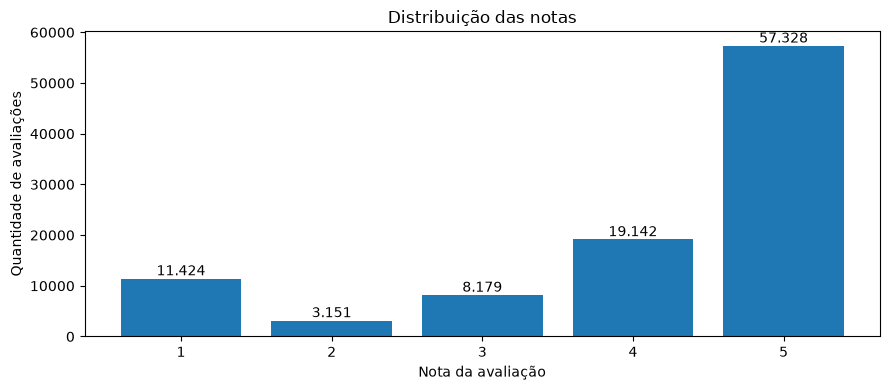

In [29]:
notas = reviews["review_score"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(notas.index.astype(str), notas.values)
ax.set(title="Distribuição das notas", xlabel="Nota da avaliação", ylabel="Quantidade de avaliações")
for i, valor in enumerate(notas.values):
    ax.text(i, valor, f"{valor:,}".replace(",", "."), ha="center", va="bottom")
plt.tight_layout()
plt.show()

,avaliacoes,com_mensagem,com_algum_texto,pct_com_mensagem,pct_com_algum_texto
review_score,,,,,
1,11424,8744,8829,76.54,77.28
2,3151,2145,2165,68.07,68.71
3,8179,3556,3643,43.48,44.54
4,19142,5970,6274,31.19,32.78
5,57328,20535,21776,35.82,37.98


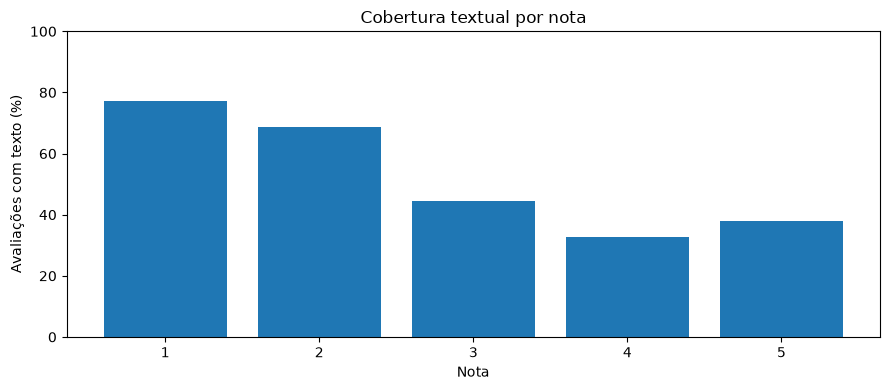

In [30]:
cobertura = reviews.groupby("review_score", dropna=False).agg(
    avaliacoes=("review_id", "size"),
    com_mensagem=("tem_mensagem", "sum"),
    com_algum_texto=("tem_algum_texto", "sum"),
)
cobertura["pct_com_mensagem"] = (100 * cobertura["com_mensagem"] / cobertura["avaliacoes"]).round(2)
cobertura["pct_com_algum_texto"] = (100 * cobertura["com_algum_texto"] / cobertura["avaliacoes"]).round(2)
display(cobertura)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(cobertura.index.astype(str), cobertura["pct_com_algum_texto"].values)
ax.set(title="Cobertura textual por nota", xlabel="Nota", ylabel="Avaliações com texto (%)", ylim=(0, 100))
plt.tight_layout()
plt.show()

**Pergunta para discussão:** o conjunto de comentários textuais tem o mesmo perfil de notas que o conjunto completo de avaliações? Se não tiver, isso precisa ser mencionado nas limitações da solução.

## 5. Análise exploratória dos textos

Para esta seção, combinaremos **título + mensagem** quando ambos existirem; caso só um deles exista, utilizaremos o campo disponível. Esta combinação é **provisória**, para análise. Não estamos definindo ainda a formatação final dos documentos indexados.

In [31]:
reviews["texto_exploratorio"] = reviews["mensagem_limpa"].copy()
apenas_titulo = reviews["tem_titulo"] & ~reviews["tem_mensagem"]
ambos = reviews["tem_titulo"] & reviews["tem_mensagem"]
reviews.loc[apenas_titulo, "texto_exploratorio"] = reviews.loc[apenas_titulo, "titulo_limpo"]
reviews.loc[ambos, "texto_exploratorio"] = (
    "Título: " + reviews.loc[ambos, "titulo_limpo"]
    + " | Comentário: " + reviews.loc[ambos, "mensagem_limpa"]
)
textuais = reviews.loc[reviews["tem_algum_texto"]].copy()
textuais["qtd_caracteres"] = textuais["texto_exploratorio"].str.len()
textuais["qtd_palavras_aprox"] = textuais["texto_exploratorio"].str.split().str.len()

display(textuais[["qtd_caracteres", "qtd_palavras_aprox"]].describe(
    percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
).round(1))
print(f"Registros textuais analisados: {len(textuais):,}")

,qtd_caracteres,qtd_palavras_aprox
count,42687.0,42687.0
mean,74.1,12.4
std,56.8,9.9
min,1.0,1.0
10%,12.0,2.0
25%,31.0,5.0
50%,59.0,10.0
75%,103.0,17.0
90%,168.0,29.0
95%,196.0,34.0


Registros textuais analisados: 42,687


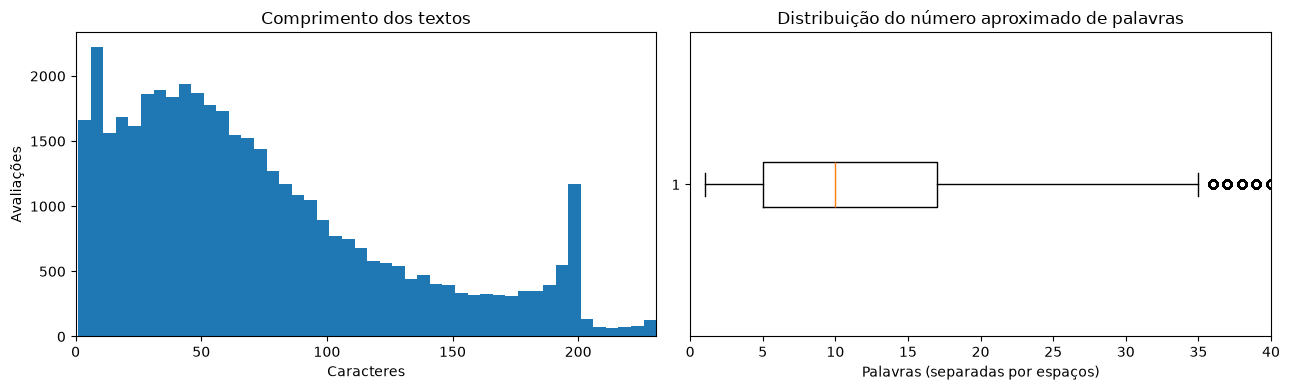

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(textuais["qtd_caracteres"].dropna(), bins=50)
axes[0].set(title="Comprimento dos textos", xlabel="Caracteres", ylabel="Avaliações")
limite = max(20, textuais["qtd_caracteres"].quantile(.99))
axes[0].set_xlim(0, limite)
axes[1].boxplot(textuais["qtd_palavras_aprox"].dropna(), orientation="horizontal")
axes[1].set(title="Distribuição do número aproximado de palavras", xlabel="Palavras (separadas por espaços)")
axes[1].set_xlim(0, max(20, textuais["qtd_palavras_aprox"].quantile(.99)))
plt.tight_layout()
plt.show()

### 5.1. Mensagens repetidas e genéricas

A comparação abaixo normaliza apenas **maiúsculas/minúsculas e espaços**. Não remove acentos, pontuação ou palavras. Isto serve para identificar padrões sem destruir a redação original.

In [33]:
textuais["texto_normalizado_diagnostico"] = (
    textuais["texto_exploratorio"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
)
frequencias_texto = textuais["texto_normalizado_diagnostico"].value_counts()
print(f"Textos distintos (normalização simples): {len(frequencias_texto):,}")
print(f"Textos que se repetem pelo menos 2 vezes: {(frequencias_texto >= 2).sum():,}")
print(f"Ocorrências excedentes dos textos repetidos: {(frequencias_texto - 1).clip(lower=0).sum():,}")
display(frequencias_texto.head(15).rename_axis("texto").reset_index(name="ocorrencias"))

Textos distintos (normalização simples): 36,479
Textos que se repetem pelo menos 2 vezes: 1,166
Ocorrências excedentes dos textos repetidos: 6,208


,texto,ocorrencias
0,muito bom,450
1,bom,380
2,recomendo,344
3,ótimo,268
4,otimo,240
5,excelente,204
6,super recomendo,133
7,ok,122
8,boa,113
9,tudo ok,74


### 5.2. Frequência exploratória de palavras

A contagem abaixo é **descritiva**, não é modelagem de tópicos nem classificador de sentimentos. O conjunto reduzido de *stopwords* é apenas um filtro para visualização; a etapa de ingestão não deverá excluir palavras automaticamente com base neste gráfico.

,palavra,frequencia
0,produto,18428
1,prazo,8475
2,entrega,6528
3,antes,5626
4,chegou,5555
5,recebi,5274
6,bom,4607
7,recomendo,4337
8,entregue,3779
9,veio,3285


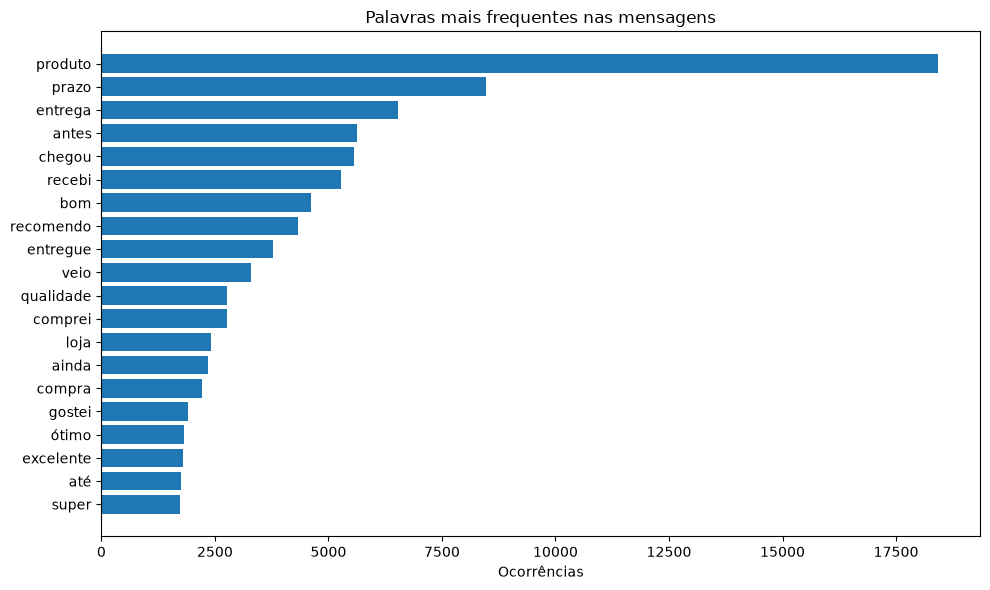

In [34]:
stopwords_basicas = {
    "a", "ao", "aos", "as", "com", "como", "da", "das", "de", "do", "dos", "e",
    "é", "em", "eu", "foi", "mais", "mas", "me", "meu", "minha", "muito", "na",
    "nas", "no", "nos", "não", "o", "os", "ou", "para", "por", "que", "se",
    "sem", "ser", "sua", "suas", "seu", "seus", "um", "uma", "uns", "umas",
    "já", "tem", "ter", "está", "estou", "são", "tudo", "bem", "pra", "pro",
}
frequencia_palavras = Counter()
for texto in textuais["mensagem_limpa"]:
    palavras = re.findall(r"\b[^\W\d_]{3,}\b", texto.lower(), flags=re.UNICODE)
    frequencia_palavras.update(p for p in palavras if p not in stopwords_basicas)

top_palavras = pd.DataFrame(frequencia_palavras.most_common(20), columns=["palavra", "frequencia"])
display(top_palavras)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_palavras["palavra"][::-1], top_palavras["frequencia"][::-1])
ax.set(title="Palavras mais frequentes nas mensagens", xlabel="Ocorrências", ylabel="")
plt.tight_layout()
plt.show()

### 5.3. Amostras qualitativas por nota

Leia alguns comentários reais para verificar se a nota está alinhada ao texto, quais temas aparecem e se há mensagens vagas. As amostras são aleatórias e reproduzíveis (`random_state=42`) — **não substituem análise de frequência**.

In [35]:
indices_amostrados = []
for nota, grupo in textuais.groupby("review_score"):
    indices_amostrados.extend(
        grupo.sample(n=min(3, len(grupo)), random_state=42).index.tolist()
    )
amostras = textuais.loc[indices_amostrados].sort_values("review_score")
display(amostras[["review_score", "review_id", "texto_exploratorio"]])

,review_score,review_id,texto_exploratorio
11740,1,c76b55c60f815fcdeeaa623af6bda90a,não foi entregue a mercadoria
93490,1,489f2b51dd763cad962012fe5d1998a7,"Título: recramação | Comentário: estou esperando a resposta do parceiro,da loja lannister e um r..."
67977,1,1796647cacbc755d9dc93263b9950d2a,Fiz a solicitação de cancelamento do pedido e não obtive resposta da empresa. Ainda por cima con...
68627,2,b9677c5ecaf9a9030e9ce79b23539688,Muito ruim na hora de devolver o dinheiro
73554,2,b4bc943faf60e1a36f13f4b6f4d00eef,Prazo para o dia 12/07 e não foi entregue
67427,2,4488aeefe49359f73c6b65bb6c831bff,"Fiz duas compras uma chegou e a outra estou com problema na entrega, não consigo contato por e-m..."
11598,3,4db72b31edfd4bc4b91020c9e0f92487,"o produto é bom, porém não resolveu o problema do ronco. Lembrando que não respondi em tempo por..."
79291,3,27e71b7a8ea675d9a06190e8dcda1fc0,essa é minha terceira compra e apesar dos imprevistos ... super recomendo !!!!!!!!!
86739,3,c29e4a84b3b36860501927116022380d,"O único problema foi que não entregaram em casa, tive que ir retirar no correio"
54574,4,76aa26669d7083c87478515dbc9900b1,Título: boa | Comentário: gostei


## 6. Possibilidades de enriquecimento com outras tabelas

Vamos inspecionar somente as tabelas úteis para metadados do RAG: pedidos, itens, produtos e tradução de categorias. **Geolocalização, clientes, vendedores e pagamentos não são necessários para esta EDA inicial.**

In [36]:
orders = pd.read_csv(
    RAW / "olist_orders_dataset.csv",
    dtype={"order_id": "string"},
)
items = pd.read_csv(
    RAW / "olist_order_items_dataset.csv",
    dtype={"order_id": "string", "product_id": "string"},
)
products = pd.read_csv(
    RAW / "olist_products_dataset.csv",
    dtype={"product_id": "string"},
)
translation = pd.read_csv(RAW / "product_category_name_translation.csv")

for nome, tabela in [("orders", orders), ("items", items), ("products", products), ("translation", translation)]:
    print(f"{nome}: {tabela.shape[0]:,} registros × {tabela.shape[1]} colunas")
    print("  Colunas:", ", ".join(tabela.columns))

orders: 99,441 registros × 8 colunas
  Colunas: order_id, customer_id, order_status, order_purchase_timestamp, order_approved_at, order_delivered_carrier_date, order_delivered_customer_date, order_estimated_delivery_date
items: 112,650 registros × 7 colunas
  Colunas: order_id, order_item_id, product_id, seller_id, shipping_limit_date, price, freight_value
products: 32,951 registros × 9 colunas
  Colunas: product_id, product_category_name, product_name_lenght, product_description_lenght, product_photos_qty, product_weight_g, product_length_cm, product_height_cm, product_width_cm
translation: 71 registros × 2 colunas
  Colunas: product_category_name, product_category_name_english


### 6.1. Relacionamento entre avaliação e pedido

A junção `reviews → orders` deve usar `order_id`. Antes disso, verificamos integridade e cardinalidade: **uma linha por pedido** em `orders`, mas um pedido pode eventualmente ter mais de uma avaliação. Assim, o *merge* esperado é `many_to_one`.

In [37]:
print("IDs de pedido duplicados em orders:", f"{orders['order_id'].duplicated().sum():,}")
print("IDs de produto duplicados em products:", f"{products['product_id'].duplicated().sum():,}")
print("Pedidos das avaliações localizados em orders:",
      f"{reviews['order_id'].isin(orders['order_id']).mean():.2%}")

# 'validate' interrompe a execução se a cardinalidade esperada não for respeitada.
reviews_orders = reviews.merge(
    orders,
    on="order_id",
    how="left",
    validate="many_to_one",
    indicator=True,
)
print("Resultado do merge:")
display(reviews_orders["_merge"].value_counts().rename("quantidade").to_frame())
print("\nStatus dos pedidos vinculados às avaliações:")
display(reviews_orders["order_status"].value_counts(dropna=False).rename("quantidade").to_frame())

IDs de pedido duplicados em orders: 0
IDs de produto duplicados em products: 0
Pedidos das avaliações localizados em orders: 100.00%
Resultado do merge:


,quantidade
_merge,
both,99224
left_only,0
right_only,0



Status dos pedidos vinculados às avaliações:


,quantidade
order_status,
delivered,96361
shipped,1043
canceled,609
unavailable,597
invoiced,313
processing,296
created,3
approved,2


### 6.2. Entrega e atrasos

Para evitar classificar como atraso uma entrega realizada **no dia previsto**, comparamos apenas as **datas** (desconsiderando o horário). A análise de atraso considera exclusivamente pedidos com data real e data estimada de entrega.

In [38]:
for coluna in ["order_delivered_customer_date", "order_estimated_delivery_date", "order_purchase_timestamp"]:
    reviews_orders[coluna + "_dt"] = pd.to_datetime(reviews_orders[coluna], errors="coerce")

reviews_orders["dias_atraso"] = (
    reviews_orders["order_delivered_customer_date_dt"].dt.normalize()
    - reviews_orders["order_estimated_delivery_date_dt"].dt.normalize()
).dt.days

entregues_com_datas = reviews_orders.loc[reviews_orders["dias_atraso"].notna()].copy()
print(f"Avaliações com dados de entrega suficientes: {len(entregues_com_datas):,}")
print(f"Percentual das avaliações totais: {len(entregues_com_datas) / len(reviews_orders):.2%}")
print("\nResumo de dias de atraso (negativo = antecipada):")
display(entregues_com_datas["dias_atraso"].describe().round(1).to_frame())

if not entregues_com_datas.empty:
    entregues_com_datas["faixa_entrega"] = pd.cut(
        entregues_com_datas["dias_atraso"],
        bins=[-np.inf, -1, 0, 3, 7, np.inf],
        labels=["Antes do prazo", "No prazo", "Atraso de 1 a 3 dias", "Atraso de 4 a 7 dias", "Atraso > 7 dias"],
    )
    relacao_entrega_nota = entregues_com_datas.groupby("faixa_entrega", observed=True).agg(
        avaliacoes=("review_score", "size"),
        nota_media=("review_score", "mean"),
    )
    display(relacao_entrega_nota.round(2))

Avaliações com dados de entrega suficientes: 96,359
Percentual das avaliações totais: 97.11%

Resumo de dias de atraso (negativo = antecipada):


,dias_atraso
count,96359.0
mean,-11.9
std,10.1
min,-147.0
25%,-17.0
50%,-12.0
75%,-7.0
max,188.0


,avaliacoes,nota_media
faixa_entrega,,
Antes do prazo,88658,4.29
No prazo,1291,4.03
Atraso de 1 a 3 dias,1856,3.29
Atraso de 4 a 7 dias,1756,2.10
Atraso > 7 dias,2798,1.70


### 6.3. Produtos e categorias sem multiplicar as avaliações

O relacionamento `orders → order_items` é **1:N**. Portanto, fazer uma junção direta das avaliações com os itens pode duplicar avaliações de pedidos com múltiplos produtos. A solução exploratória é **agregar itens por pedido antes do merge**.

In [39]:
print("Itens no dataset:", f"{len(items):,}")
print("Pedidos distintos em items:", f"{items['order_id'].nunique():,}")
print("Produtos distintos em items:", f"{items['product_id'].nunique():,}")

itens_por_pedido = items.groupby("order_id", as_index=False).agg(
    quantidade_itens=("product_id", "size"),
    produtos_distintos=("product_id", "nunique"),
)
print("Pedidos após agregação:", f"{len(itens_por_pedido):,}")

reviews_enriquecidas = reviews_orders.merge(
    itens_por_pedido, on="order_id", how="left", validate="many_to_one"
)
assert len(reviews_enriquecidas) == len(reviews), "A junção alterou a quantidade de avaliações!"
print(f"Total preservado após merge: {len(reviews_enriquecidas):,}")
display(reviews_enriquecidas[["review_score", "quantidade_itens", "produtos_distintos"]].describe().round(2))

Itens no dataset: 112,650
Pedidos distintos em items: 98,666
Produtos distintos em items: 32,951
Pedidos após agregação: 98,666
Total preservado após merge: 99,224


,review_score,quantidade_itens,produtos_distintos
count,99224.00,98465.00,98465.00
mean,4.09,1.14,1.04
std,1.35,0.53,0.23
min,1.00,1.00,1.00
25%,4.00,1.00,1.00
50%,5.00,1.00,1.00
75%,5.00,1.00,1.00
max,5.00,21.00,8.00


In [40]:
# Adiciona a categoria ao item de pedido, preservando a cardinalidade 1:N dos itens.
itens_categorias = items[["order_id", "product_id"]].merge(
    products[["product_id", "product_category_name"]],
    on="product_id", how="left", validate="many_to_one"
)

categorias_por_pedido = (
    itens_categorias.groupby("order_id")["product_category_name"]
    .agg(lambda serie: " | ".join(sorted(set(serie.dropna().astype(str)))))
    .rename("categorias_pedido")
    .reset_index()
)

reviews_enriquecidas = reviews_enriquecidas.merge(
    categorias_por_pedido, on="order_id", how="left", validate="many_to_one"
)
assert len(reviews_enriquecidas) == len(reviews), "A junção de categorias duplicou avaliações!"

print("Categorias distintas de produtos:", products["product_category_name"].nunique())
print("Categorias com tradução disponível:", translation["product_category_name"].nunique())
print("Avaliações com pelo menos uma categoria identificada:",
      f"{reviews_enriquecidas['categorias_pedido'].fillna('').ne('').sum():,}")
display(reviews_enriquecidas[["order_id", "review_score", "categorias_pedido"]].head())

Categorias distintas de produtos: 73
Categorias com tradução disponível: 71
Avaliações com pelo menos uma categoria identificada: 97,077


,order_id,review_score,categorias_pedido
0,73fc7af87114b39712e6da79b0a377eb,4,esporte_lazer
1,a548910a1c6147796b98fdf73dbeba33,5,informatica_acessorios
2,f9e4b658b201a9f2ecdecbb34bed034b,5,informatica_acessorios
3,658677c97b385a9be170737859d3511b,5,ferramentas_jardim
4,8e6bfb81e283fa7e4f11123a3fb894f1,5,esporte_lazer


## 7. Conclusões da EDA e decisões para o RAG

Os resultados desta seção são **calculados no momento da execução**. Use-os para justificar as decisões de ingestão na documentação. Não é necessário tomar todas as decisões antes de ler os indicadores.

In [41]:
resumo_final = pd.DataFrame([
    ("Avaliações originais", len(reviews)),
    ("Com mensagem", int(reviews["tem_mensagem"].sum())),
    ("Com título e/ou mensagem", int(reviews["tem_algum_texto"].sum())),
    ("Somente título", int(apenas_titulo.sum())),
    ("Sem qualquer texto", int((~reviews["tem_algum_texto"]).sum())),
    ("IDs de avaliação distintos", int(reviews["review_id"].nunique())),
    ("Textos de diagnóstico distintos", int(textuais["texto_normalizado_diagnostico"].nunique())),
    ("Pedidos vinculados encontrados", int(reviews_orders["_merge"].eq("both").sum())),
    ("Avaliações com datas de entrega", int(reviews_orders["dias_atraso"].notna().sum())),
], columns=["indicador", "valor"])
display(resumo_final)

,indicador,valor
0,Avaliações originais,99224
1,Com mensagem,40950
2,Com título e/ou mensagem,42687
3,Somente título,1737
4,Sem qualquer texto,56537
5,IDs de avaliação distintos,98410
6,Textos de diagnóstico distintos,36479
7,Pedidos vinculados encontrados,99224
8,Avaliações com datas de entrega,96359


In [42]:
# Diagnóstico de unicidade dos identificadores

pares = reviews.groupby(
    ["review_id", "order_id"],
    dropna=False
).size()

print("Total de avaliações:", len(reviews))
print("Pares review_id + order_id únicos:", len(pares))
print("Excedente de pares repetidos:", int((pares - 1).clip(lower=0).sum()))

print(
    "review_id associados a múltiplos pedidos:",
    int(
        (reviews.groupby("review_id")["order_id"].nunique() > 1).sum()
    )
)

print(
    "Pedidos com múltiplas avaliações:",
    int(
        (reviews.groupby("order_id").size() > 1).sum()
    )
)

Total de avaliações: 99224
Pares review_id + order_id únicos: 99224
Excedente de pares repetidos: 0
review_id associados a múltiplos pedidos: 789
Pedidos com múltiplas avaliações: 547



## Conclusões e decisões técnicas

A análise exploratória identificou 99.224 avaliações, das quais 42.687 possuem pelo menos um campo textual preenchido.

### Principais decisões

1. **Seleção:** utilizar inicialmente avaliações que contenham título e/ou mensagem.
2. **Granularidade:** representar cada avaliação como um documento independente.
3. **Identificação:** utilizar a combinação `review_id` e `order_id`, que apresentou unicidade em todos os registros.
4. **Limpeza:** tratar valores ausentes, espaços e quebras de linha, preservando o significado original dos comentários.
5. **Duplicidades:** não eliminar automaticamente comentários iguais associados a avaliações distintas.
6. **Metadados:** considerar nota, datas, informações de entrega e categorias dos produtos.
7. **Chunking:** começar com documentos completos, considerando o tamanho reduzido das avaliações.
8. **Avaliação:** verificar a qualidade da recuperação, a fundamentação das respostas e as limitações de perguntas sobre frequência.

### Limitações identificadas

- Apenas 43,02% das avaliações possuem algum conteúdo textual.
- A disponibilidade de comentários varia conforme a nota, produzindo possível viés de seleção.
- Textos genéricos ou repetitivos podem reduzir a diversidade dos resultados recuperados.
- A recuperação por similaridade semântica não permite, isoladamente, estimar a frequência global de reclamações.

Essas conclusões fundamentarão a construção da base de conhecimento e serão reavaliadas durante os testes do pipeline RAG.


**Referência teórica:** Lewis, P. et al. (2020). *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks*. [arXiv:2005.11401](https://arxiv.org/abs/2005.11401).